Data preprocessed successfully:
Timeframe: 2020-08-30 to 2022-08-21
Observations: 104 weeks, Channels: 7

PyMC Model constructed successfully.

Starting MCMC Sampling...


Output()

Output()


=== PARAMETER DIAGNOSTICS ===
                  mean     sd  hdi_3%  hdi_97%  r_hat  ess_bulk
beta_channel[0]  0.047  0.047   0.000    0.132    1.0    2409.0
beta_channel[1]  0.111  0.064   0.001    0.218    1.0    2976.0
beta_channel[2]  0.142  0.072   0.006    0.261    1.0    2599.0
beta_channel[3]  0.087  0.067   0.000    0.206    1.0    3054.0
beta_channel[4]  0.083  0.057   0.000    0.182    1.0    1988.0
beta_channel[5]  0.140  0.075   0.000    0.261    1.0    2662.0
beta_channel[6]  0.161  0.086   0.000    0.301    1.0    2419.0
alpha[0]         0.557  0.237   0.142    0.951    1.0    4373.0
alpha[1]         0.447  0.229   0.059    0.868    1.0    5516.0
alpha[2]         0.347  0.199   0.035    0.721    1.0    4076.0
alpha[3]         0.396  0.233   0.029    0.808    1.0    4741.0
alpha[4]         0.408  0.209   0.043    0.782    1.0    4405.0
alpha[5]         0.409  0.209   0.051    0.788    1.0    5041.0
alpha[6]         0.391  0.219   0.034    0.796    1.0    5020.0
intercept

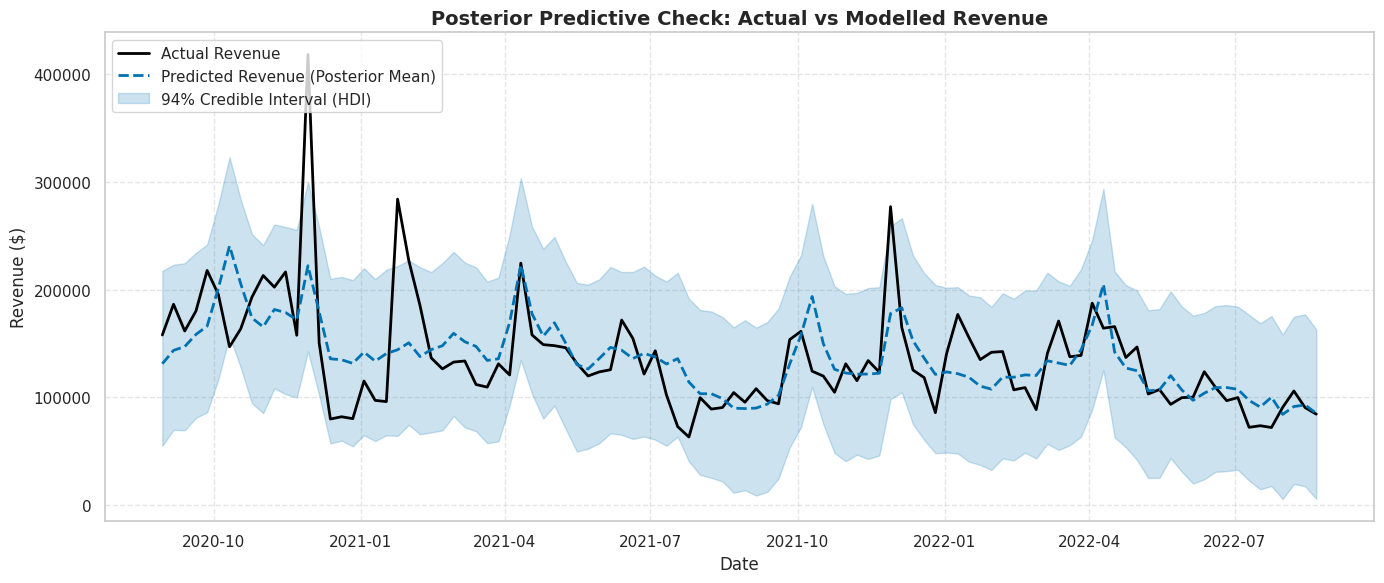


=== FINAL MEDIA MIX MODEL INSIGHTS & ROI SUMMARY ===
  Channel Adstock Alpha (Decay) Total Spend ($) Attributed Rev ($) Mean ROI ROI 94% HDI Low ROI 94% HDI High
Channel 1                 0.557     $129,542.90        $299,209.80    2.31x           0.00x            6.46x
Channel 2                 0.447      $35,738.66      $1,014,130.33   28.38x           0.00x           55.76x
Channel 3                 0.347   $2,028,746.51      $2,414,530.95    1.19x           0.04x            2.18x
Channel 4                 0.396     $719,174.22      $1,157,464.67    1.61x           0.00x            3.79x
Channel 5                 0.408     $891,863.59        $933,697.05    1.05x           0.00x            2.30x
Channel 6                 0.409     $526,624.70        $912,930.61    1.73x           0.01x            3.24x
Channel 7                 0.391   $2,880,942.21      $2,477,441.80    0.86x           0.01x            1.61x


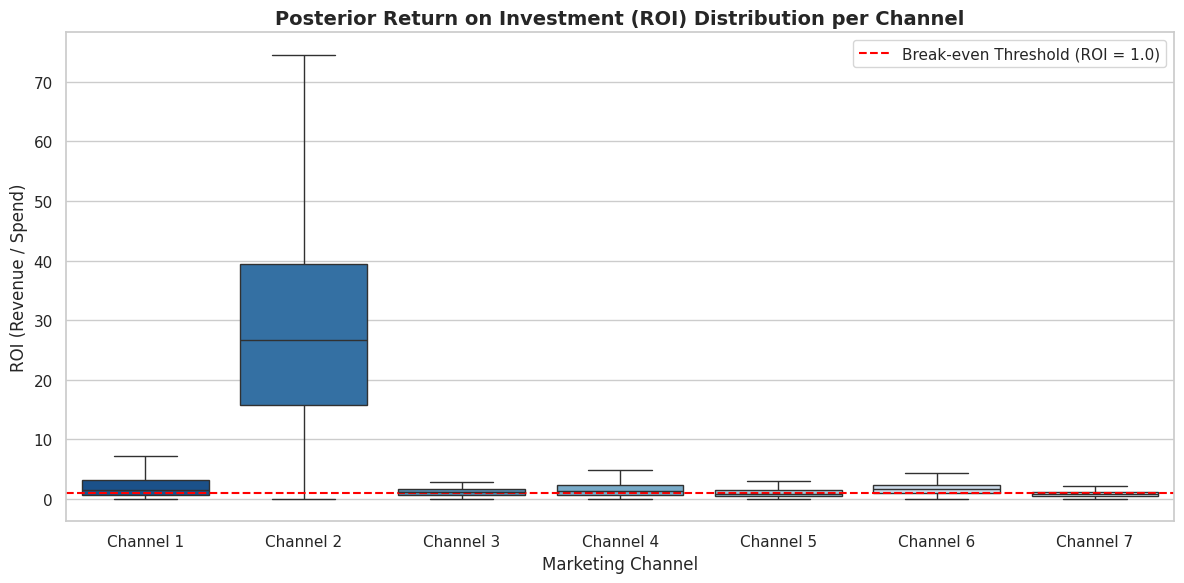

In [1]:
# ==============================================================================
# COMPLETE BAYESIAN MEDIA MIX MODEL (MMM) IN PYMC
# HAMS Data Science Challenge
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from sklearn.metrics import r2_score, mean_absolute_percentage_error, root_mean_squared_error

# Set plot style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# ------------------------------------------------------------------------------
# STEP 1: DATA LOADING & PREPROCESSING
# ------------------------------------------------------------------------------
file_path = 'MMM_test_data.csv'
df = pd.read_csv(file_path)

# Parse dates and sort chronologically
df['start_of_week'] = pd.to_datetime(df['start_of_week'], format='%d-%m-%y')
df = df.sort_values('start_of_week').reset_index(drop=True)

channel_cols = [f'spend_channel_{i}' for i in range(1, 8)]
n_channels = len(channel_cols)

# Scale features for MCMC stability
max_revenue = df['revenue'].max()
max_spends = df[channel_cols].max()

y_scaled = (df['revenue'] / max_revenue).values
X_spend_scaled = (df[channel_cols] / max_spends).values

# Build Lag Matrix for Geometric Adstock (l_max = 8 weeks carryover)
def build_lag_matrix(x, l_max=8):
    n_obs, n_cols = x.shape
    lags = []
    for l in range(l_max):
        if l == 0:
            lags.append(x)
        else:
            lagged = np.vstack([np.zeros((l, n_cols)), x[:-l, :]])
            lags.append(lagged)
    return np.stack(lags, axis=1)

l_max = 8
X_lags = build_lag_matrix(X_spend_scaled, l_max=l_max)
n_obs, _, _ = X_lags.shape

print("Data preprocessed successfully:")
print(f"Timeframe: {df['start_of_week'].min().strftime('%Y-%m-%d')} to {df['start_of_week'].max().strftime('%Y-%m-%d')}")
print(f"Observations: {n_obs} weeks, Channels: {n_channels}")

# ------------------------------------------------------------------------------
# STEP 2: PYMC BAYESIAN MODEL DEFINITION
# ------------------------------------------------------------------------------
with pm.Model() as mmm_model:
    # 2.1 Priors
    intercept = pm.Normal('intercept', mu=0.5, sigma=0.2)
    beta_trend = pm.Normal('beta_trend', mu=0.0, sigma=0.1)

    # Marketing channels have positive impact on sales -> HalfNormal prior
    beta_channel = pm.HalfNormal('beta_channel', sigma=0.5, shape=n_channels)

    # Adstock retention rate alpha in range [0, 1]
    alpha = pm.Beta('alpha', alpha=2.0, beta=2.0, shape=n_channels)

    sigma = pm.Exponential('sigma', lam=10.0)

    # 2.2 Geometric Adstock Transformation
    lags = np.arange(l_max)
    w_raw = alpha[None, :] ** lags[:, None]
    w_norm = w_raw / pt.sum(w_raw, axis=0, keepdims=True)

    # Adstocked spend computation across lag dimension
    X_adstocked = pt.sum(X_lags * w_norm[None, :, :], axis=1)

    # 2.3 Likelihood Equation
    time_index = np.linspace(0, 1, n_obs)
    mu = (
        intercept
        + beta_trend * time_index
        + pt.dot(X_adstocked, beta_channel)
    )

    y_obs = pm.Normal('y_obs', mu=mu, sigma=sigma, observed=y_scaled)

print("\nPyMC Model constructed successfully.")

# ------------------------------------------------------------------------------
# STEP 3: MCMC POSTERIOR SAMPLING & DIAGNOSTICS
# ------------------------------------------------------------------------------
with mmm_model:
    print("\nStarting MCMC Sampling...")
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.95,
        random_seed=42,
        return_inferencedata=True
    )

    posterior_predictive = pm.sample_posterior_predictive(
        idata,
        random_seed=42
    )

idata.extend(posterior_predictive)

# Check Convergence
summary_df = az.summary(
    idata,
    var_names=['beta_channel', 'alpha', 'intercept', 'beta_trend']
)

print("\n=== PARAMETER DIAGNOSTICS ===")
print(summary_df[['mean', 'sd', 'hdi_3%', 'hdi_97%', 'r_hat', 'ess_bulk']])

max_rhat = summary_df['r_hat'].max()
print(f"\nMax R-hat across parameters: {max_rhat:.3f}")
if max_rhat <= 1.05:
    print("STATUS: Model MCMC chains converged successfully!")

# ------------------------------------------------------------------------------
# STEP 4: MODEL EVALUATION & PREDICTIVE ACCURACY
# ------------------------------------------------------------------------------
y_pred_scaled = idata.posterior_predictive['y_obs'].mean(dim=['chain', 'draw']).values
y_pred = y_pred_scaled * max_revenue
y_true = df['revenue'].values

r2 = r2_score(y_true, y_pred)
mape = mean_absolute_percentage_error(y_true, y_pred)
rmse = root_mean_squared_error(y_true, y_pred)

print("\n=== MODEL ACCURACY METRICS ===")
print(f"R² Score: {r2:.4f}")
print(f"MAPE: {mape * 100:.2f}%")
print(f"RMSE: ${rmse:,.2f}")

# Posterior Predictive Check Plot
plt.figure(figsize=(14, 6))
plt.plot(df['start_of_week'], y_true, label='Actual Revenue', color='black', linewidth=2)
plt.plot(df['start_of_week'], y_pred, label='Predicted Revenue (Posterior Mean)', color='#0072B2', linestyle='--', linewidth=2)

hdi_bounds = az.hdi(idata.posterior_predictive['y_obs'])['y_obs'].values * max_revenue
plt.fill_between(
    df['start_of_week'],
    hdi_bounds[:, 0],
    hdi_bounds[:, 1],
    color='#0072B2',
    alpha=0.2,
    label='94% Credible Interval (HDI)'
)

plt.title('Posterior Predictive Check: Actual vs Modelled Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# STEP 5: CHANNEL ATTRIBUTION & ROI ANALYSIS
# ------------------------------------------------------------------------------
beta_samples = idata.posterior['beta_channel'].values.reshape(-1, n_channels)
alpha_samples = idata.posterior['alpha'].values.reshape(-1, n_channels)

n_draws = beta_samples.shape[0]
attributed_rev_samples = np.zeros((n_draws, n_channels))

def np_compute_adstock(x_lags, alpha):
    lags_arr = np.arange(l_max)
    w = alpha[None, :] ** lags_arr[:, None]
    w_norm = w / np.sum(w, axis=0, keepdims=True)
    return np.sum(x_lags * w_norm[None, :, :], axis=1)

for d in range(n_draws):
    adstocked_draw = np_compute_adstock(X_lags, alpha_samples[d])
    for c in range(n_channels):
        attributed_rev_samples[d, c] = np.sum(adstocked_draw[:, c] * beta_samples[d, c]) * max_revenue

total_spends = df[channel_cols].sum().values
roi_samples = attributed_rev_samples / total_spends[np.newaxis, :]

mean_roi = np.mean(roi_samples, axis=0)
hdi_roi = az.hdi(roi_samples.reshape(4, 1000, n_channels), hdi_prob=0.94)
mean_attributed_rev = np.mean(attributed_rev_samples, axis=0)
mean_alpha = np.mean(alpha_samples, axis=0)

roi_results_df = pd.DataFrame({
    'Channel': [f'Channel {i}' for i in range(1, 8)],
    'Adstock Alpha (Decay)': mean_alpha,
    'Total Spend ($)': total_spends,
    'Attributed Rev ($)': mean_attributed_rev,
    'Mean ROI': mean_roi,
    'ROI 94% HDI Low': hdi_roi[:, 0],
    'ROI 94% HDI High': hdi_roi[:, 1]
})

print("\n=== FINAL MEDIA MIX MODEL INSIGHTS & ROI SUMMARY ===")
print(roi_results_df.to_string(index=False, formatters={
    'Adstock Alpha (Decay)': '{:.3f}'.format,
    'Total Spend ($)': '${:,.2f}'.format,
    'Attributed Rev ($)': '${:,.2f}'.format,
    'Mean ROI': '{:.2f}x'.format,
    'ROI 94% HDI Low': '{:.2f}x'.format,
    'ROI 94% HDI High': '{:.2f}x'.format
}))

# Visualizing ROI Distributions
plt.figure(figsize=(12, 6))
roi_df_plot = pd.DataFrame(roi_samples, columns=[f'Channel {i}' for i in range(1, 8)])
sns.boxplot(data=roi_df_plot, palette='Blues_r', showfliers=False)
plt.axhline(1.0, color='red', linestyle='--', linewidth=1.5, label='Break-even Threshold (ROI = 1.0)')

plt.title('Posterior Return on Investment (ROI) Distribution per Channel', fontsize=14, fontweight='bold')
plt.xlabel('Marketing Channel')
plt.ylabel('ROI (Revenue / Spend)')
plt.legend()
plt.tight_layout()
plt.show()

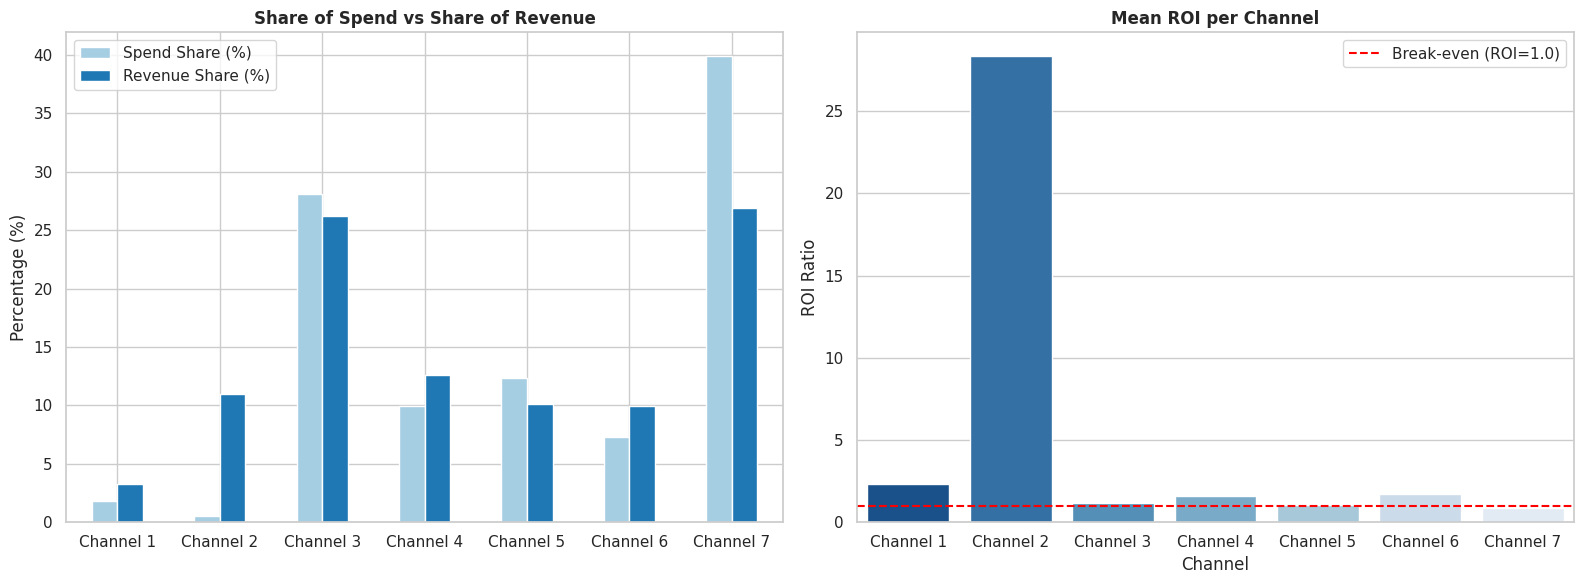

In [6]:
# ==============================================================================
# VISUALIZATION: SHARE OF SPEND VS REVENUE & CHANNEL ROI
# ==============================================================================

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Dynamic calculation of Spend Share (%) and Revenue Share (%)
spend_share = total_spends / total_spends.sum() * 100
rev_share = mean_attributed_rev / mean_attributed_rev.sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# ------------------------------------------------------------------------------
# 1. Share of Spend vs Share of Revenue
# ------------------------------------------------------------------------------
shares_df = pd.DataFrame({
    'Spend Share (%)': spend_share,
    'Revenue Share (%)': rev_share
}, index=[f'Channel {i}' for i in range(1, 8)])

shares_df.plot(kind='bar', ax=ax[0], color=['#a6cee3', '#1f78b4'])
ax[0].set_title('Share of Spend vs Share of Revenue', fontsize=12, fontweight='bold')
ax[0].set_ylabel('Percentage (%)')
ax[0].tick_params(axis='x', rotation=0)

# ------------------------------------------------------------------------------
# 2. Mean ROI per Channel (Seaborn v0.14+ Compatible)
# ------------------------------------------------------------------------------
sns.barplot(
    data=roi_results_df,
    x='Channel',
    y='Mean ROI',
    hue='Channel',
    palette='Blues_r',
    dodge=False,
    ax=ax[1]
)

# Remove duplicate legend generated by hue
if ax[1].get_legend():
    ax[1].get_legend().remove()

# Add Break-even threshold line (ROI = 1.0)
ax[1].axhline(1.0, color='red', linestyle='--', label='Break-even (ROI=1.0)')
ax[1].set_title('Mean ROI per Channel', fontsize=12, fontweight='bold')
ax[1].set_ylabel('ROI Ratio')
ax[1].legend()

plt.tight_layout()
plt.show()


--- Parameter Summary & Convergence Diagnostics ---
                  mean     sd  hdi_3%  hdi_97%  r_hat  ess_bulk
beta_channel[0]  0.047  0.047   0.000    0.132    1.0    2409.0
beta_channel[1]  0.111  0.064   0.001    0.218    1.0    2976.0
beta_channel[2]  0.142  0.072   0.006    0.261    1.0    2599.0
beta_channel[3]  0.087  0.067   0.000    0.206    1.0    3054.0
beta_channel[4]  0.083  0.057   0.000    0.182    1.0    1988.0
beta_channel[5]  0.140  0.075   0.000    0.261    1.0    2662.0
beta_channel[6]  0.161  0.086   0.000    0.301    1.0    2419.0
alpha[0]         0.557  0.237   0.142    0.951    1.0    4373.0
alpha[1]         0.447  0.229   0.059    0.868    1.0    5516.0
alpha[2]         0.347  0.199   0.035    0.721    1.0    4076.0
alpha[3]         0.396  0.233   0.029    0.808    1.0    4741.0
alpha[4]         0.408  0.209   0.043    0.782    1.0    4405.0
alpha[5]         0.409  0.209   0.051    0.788    1.0    5041.0
alpha[6]         0.391  0.219   0.034    0.796    1

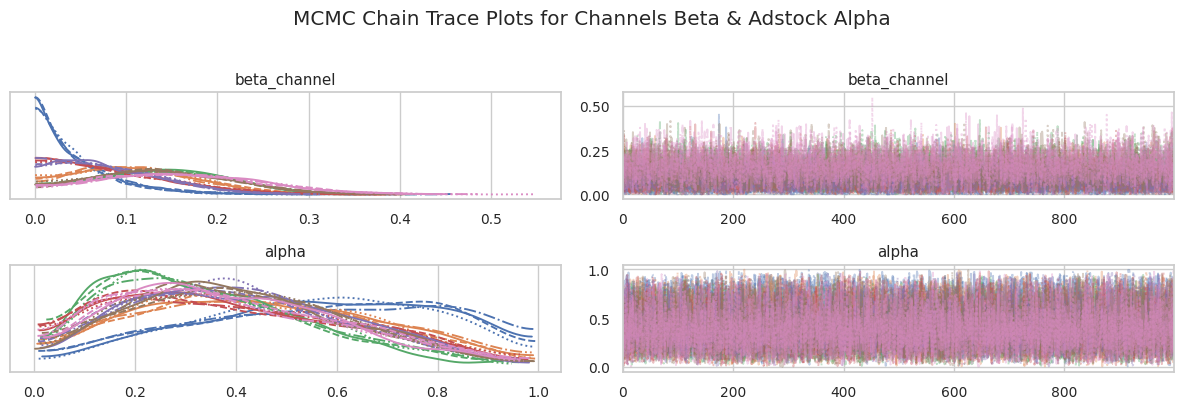

In [7]:
# ==============================================================================
# PART 3: MODEL FITTING & CONVERGENCE DIAGNOSTICS
# ==============================================================================

import arviz as az
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 3.1 Convergence Check (R-hat & Effective Sample Size)
# ------------------------------------------------------------------------------
summary_df = az.summary(
    idata,
    var_names=['beta_channel', 'alpha', 'intercept', 'beta_trend']
)

print("\n--- Parameter Summary & Convergence Diagnostics ---")
print(summary_df[['mean', 'sd', 'hdi_3%', 'hdi_97%', 'r_hat', 'ess_bulk']])

# Check MCMC convergence condition
max_rhat = summary_df['r_hat'].max()
print(f"\nMaximum R-hat value across parameters: {max_rhat:.3f}")
if max_rhat <= 1.05:
    print("CONVERGENCE STATUS: All MCMC chains converged successfully (R-hat <= 1.05)!")
else:
    print("CONVERGENCE WARNING: Some parameters show potential non-convergence. Consider increasing tuning steps.")

# ------------------------------------------------------------------------------
# 3.2 Visual Trace Plots
# ------------------------------------------------------------------------------
az.plot_trace(idata, var_names=['beta_channel', 'alpha'], compact=True)
plt.suptitle('MCMC Chain Trace Plots for Channels Beta & Adstock Alpha', y=1.02)
plt.tight_layout()
plt.show()